# Rhythm ratio distributions

The rhythm ratio of a dyad of durations `(d1, d2)` is `r = d1 / (d1 + d2)`, where 0.5 corresponds to perfect isochrony.

Each row shows a KDE of the rhythm ratios of individual dyads, pooled across all birds (black), together with `N_BIRD_SAMPLE` = 20 random birds in the background. To balance the amount of data per bird, we filter out the 10% shortest and 10% longest chunks per bird (`TRIM_FRAC`, by dyad count) and then sample `N_CHUNK_SAMPLE` = 10 of the remaining chunks. The y-axis is scaled to the pooled density, so the curve of a single bird may run off the top.

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from viz.utils import set_mpl_style
set_mpl_style()

from data import load_dyads
from constants import DATASETS

from viz.rows import row_height_ratios, annotate_row_groups, clean_density_yaxis
from fig2_settings import SECTIONS, build_row_specs, SAMPLE_COLOR

In [2]:
# Plotting specs
row_specs = build_row_specs(SECTIONS)
ROW_HEIGHT_RATIOS = row_height_ratios(row_specs, header_ratio=0.12)

N_BIRD_SAMPLE = 20
N_CHUNK_SAMPLE = 10
TRIM_FRAC = 0.1
SAMPLE_SEED = 0

In [3]:
def load_dyad_ratios(datasets, rhythm_type, rng, n_chunk_sample=N_CHUNK_SAMPLE, trim_frac=TRIM_FRAC):
    frames = []
    for dataset_id in datasets:
        bird_id_col = DATASETS[dataset_id]['bird_id_col']
        dyads = load_dyads(dataset_id, rhythm_type, bird_id_col=bird_id_col)
        frames.append(pd.DataFrame({
            'bird_id': dyads[bird_id_col],
            'chunk_idx': dyads['chunk_idx'],
            'ratio': dyads['duration_1'] / (dyads['duration_1'] + dyads['duration_2']),
        }))
    df = pd.concat(frames, ignore_index=True).dropna(subset=['bird_id'])
    df = df[~df['bird_id'].astype(str).str.endswith('-tutee')]

    sampled = []
    for _, group in df.groupby('bird_id'):
        # drop the shortest/longest `trim_frac` chunks (by dyad count) before sampling
        lengths = group.groupby('chunk_idx').size().sort_values()
        n_trim = int(len(lengths) * trim_frac)
        eligible = lengths.iloc[n_trim:len(lengths) - n_trim].index if n_trim else lengths.index
        chosen = rng.choice(eligible, size=min(n_chunk_sample, len(eligible)), replace=False)
        sampled.append(group[group['chunk_idx'].isin(chosen)])
    return pd.concat(sampled, ignore_index=True)

rng = np.random.default_rng(0)
load_dyad_ratios(['bvs'], 'syll_dur', rng).head()

,bird_id,chunk_idx,ratio
0,bvs-125,2,0.525773
1,bvs-125,2,0.500000
2,bvs-125,2,0.541177
3,bvs-125,2,0.371425
4,bvs-125,2,0.605506


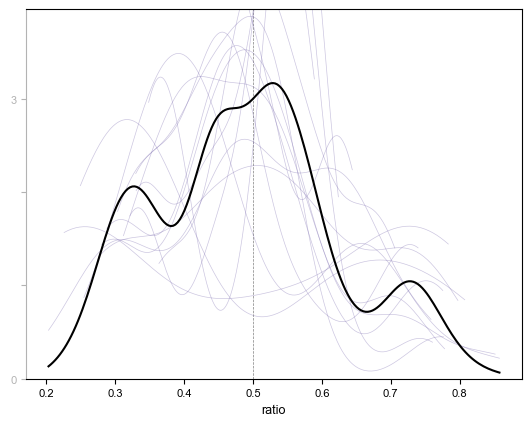

In [4]:
def plot_ratio_ax(ax, datasets, rhythm_type, rng, color=SAMPLE_COLOR, n_bird_sample=N_BIRD_SAMPLE, n_chunk_sample=N_CHUNK_SAMPLE, trim_frac=TRIM_FRAC):
    ratios = load_dyad_ratios(datasets, rhythm_type, rng, n_chunk_sample=n_chunk_sample, trim_frac=trim_frac)
    bird_ids = ratios['bird_id'].unique()
    sample_ids = rng.choice(bird_ids, size=min(n_bird_sample, len(bird_ids)), replace=False)
    for bird_id in sample_ids:
        r = ratios.loc[ratios['bird_id'] == bird_id, 'ratio']
        if r.nunique() > 1:
            sns.kdeplot(r, color=color, lw=0.5, alpha=0.4, cut=0, ax=ax, legend=False)

    sns.kdeplot(ratios['ratio'], color='k', lw=1.5, cut=0, ax=ax, legend=False)
    peak = ax.get_lines()[-1].get_ydata().max()
    ax.set_ylim(0, peak * 1.25)
    ax.axvline(0.5, c='.5', lw=.5, ls='--', zorder=0)
    clean_density_yaxis(ax)

plot_ratio_ax(plt.gca(), ['ns'], 'syll_ioi', rng)

In [5]:
def plot_ratio_column(
    axes, row_specs, color=SAMPLE_COLOR, n_bird_sample=N_BIRD_SAMPLE, n_chunk_sample=N_CHUNK_SAMPLE, trim_frac=TRIM_FRAC,
    seed=SAMPLE_SEED, show_row_labels=True, legend=True,
    legend_loc='upper left', legend_bbox_to_anchor=(1.02, 1), legend_ax='first',
):
    rng = np.random.default_rng(seed)
    first_data_ax, last_data_ax = None, None
    for ax, (kind, row_label, spec) in zip(axes, row_specs):
        if kind == 'header':
            ax.axis('off')
            continue
        datasets, rhythm_type = spec
        plot_ratio_ax(ax, datasets, rhythm_type, rng, color=color, n_bird_sample=n_bird_sample, n_chunk_sample=n_chunk_sample, trim_frac=trim_frac)
        first_data_ax = first_data_ax or ax
        last_data_ax = ax
        if show_row_labels:
            ax.set_ylabel(row_label, rotation=0, ha='right', va='center', fontsize=7, labelpad=6)
    if legend and first_data_ax is not None:
        handles = [
            plt.Line2D([0], [0], color=color, lw=1, alpha=0.6, label=f'Single bird ({n_bird_sample}x)'),
            plt.Line2D([0], [0], color='k', lw=1.5, label='All birds pooled'),
        ]
        anchor_ax = first_data_ax if legend_ax == 'first' else last_data_ax
        anchor_ax.legend(
            handles=handles, loc=legend_loc, bbox_to_anchor=legend_bbox_to_anchor, fontsize=7,
            frameon=True, title_fontsize=7,
        )
    return axes

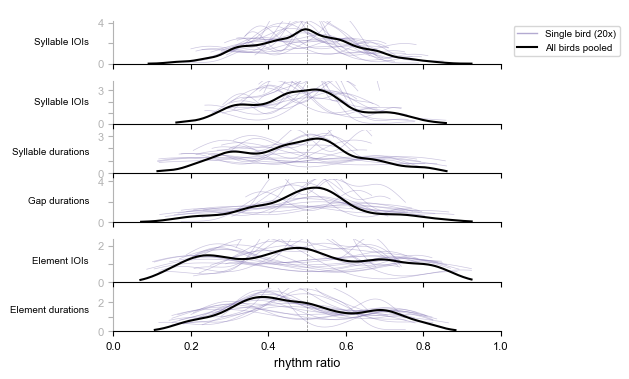

In [6]:
fig, axes = plt.subplots(
    len(row_specs), 1, figsize=(5, 0.5 * sum(ROW_HEIGHT_RATIOS) + 1),
    gridspec_kw=dict(height_ratios=ROW_HEIGHT_RATIOS), sharex=True
)
plot_ratio_column(axes, row_specs)
axes[-1].set_xlim(0, 1)
axes[-1].set_xlabel('rhythm ratio')
sns.despine()